## Two Moons: Probly (Unsicherheit) vs. SHAP/shapiq (Attribution)
Frage 1 (probly): *Wo* ist das Modell unsicher?

Frage 2 (shapiq): *Welches Feature* treibt Vorhersage bzw. Unsicherheit?

* **Daten-Setup:** Generierung von 500 zweidimensionalen Datenpunkten (`make_moons`) und Konvertierung in PyTorch-Tensoren (`X_t`, `y_t`).
* **MC Dropout:** Erstellung eines Neuronalen Netzes (`MLPClassifier`), bei dem Dropout-Maskierungen während des Trainings und der Inference aktiv bleiben (`p=0.3`), um Vorhersagestreuung zu ermöglichen.
* **Deep Ensemble:** Erzeugung eines Ensembles aus 5 unabhängigen `MLPClassifier`-Instanzen zur Erfassung epistemischer Unsicherheit.

In [1]:
from __future__ import annotations
import numpy as np, torch, matplotlib.pyplot as plt
from torch import nn
from sklearn.datasets import make_moons
import shapiq
from probly.representer import representer
from probly.transformation import dropout, ensemble
from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty

torch.manual_seed(0); np.random.seed(0)
X, y = make_moons(n_samples=500, noise=0.1, random_state=0)
X_t, y_t = torch.from_numpy(X).float(), torch.from_numpy(y).long()

def train(model, epochs=300, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        nn.functional.cross_entropy(model(X_t), y_t).backward()
        opt.step()
    model.eval()                                          # Dropout bleibt in probly aktiv

dropout_model = dropout(MLPClassifier(), p=0.3, predictor_type="logit_classifier", shared_mask=True)
train(dropout_model)

ens_model = ensemble(MLPClassifier(), num_members=5, predictor_type="logit_classifier")
for member in ens_model:
    train(member)

## Unsicherheit mit probly
Prädiktive Gesamtunsicherheit (*Total Uncertainty*) für beide probabilistischen Ansätze im 2D-Eingaberaum visualisiert:
* **MC Dropout:** Verwendet ein `representer`-Objekt mit 200 stochastischen Forward-Passes (`num_samples=200`), um die Streuung der Vorhersagen unter variierenden Dropout-Masken zu erfassen.
* **Deep Ensemble:** Aggregiert die Vorhersagen der 5 trainierten Ensemble-Mitglieder, ohne dass ein zusätzliches Sampling erforderlich ist.

## Interpretation der Unsicherheitsplots

* **Höchste Unsicherheit an der Entscheidungsgrenze:** Beide Methoden zeigen die maximale Unsicherheit (gelbe Zone, Entropie $\approx 0.69$, was dem Maximum einer binären Entscheidung entspricht) exakt im Übergangsbereich zwischen den beiden Mondsicheln.
* **Hohe Konfidenz in Datenclustern:** Innerhalb der dicht besetzten Datenpunkte (Klasse 0 und 1) fällt die Unsicherheit bei beiden Verfahren auf nahezu $0.00$ ab (dunkelvioletter Bereich).
* **Unterschiede bei der Extrapolation (Out-of-Distribution):**
  * **Deep Ensemble:** Die Zone hoher Unsicherheit erstreckt sich als schmaler, scharf abgegrenzter Korridor weit über die Trainingsdaten hinaus. Das Ensemble ist sich nur entlang der gemeinsamen Trennlinie der 5 Modellinstanzen unsicher.
  * **MC Dropout:** Erzeugt ein flächigeres und weicheres Unsicherheitsfeld außerhalb der Datenbereiche. Die stochastischen Neuronen-Ausfälle führen zu variableren Entscheidungsgrenzen im leeren Raum.

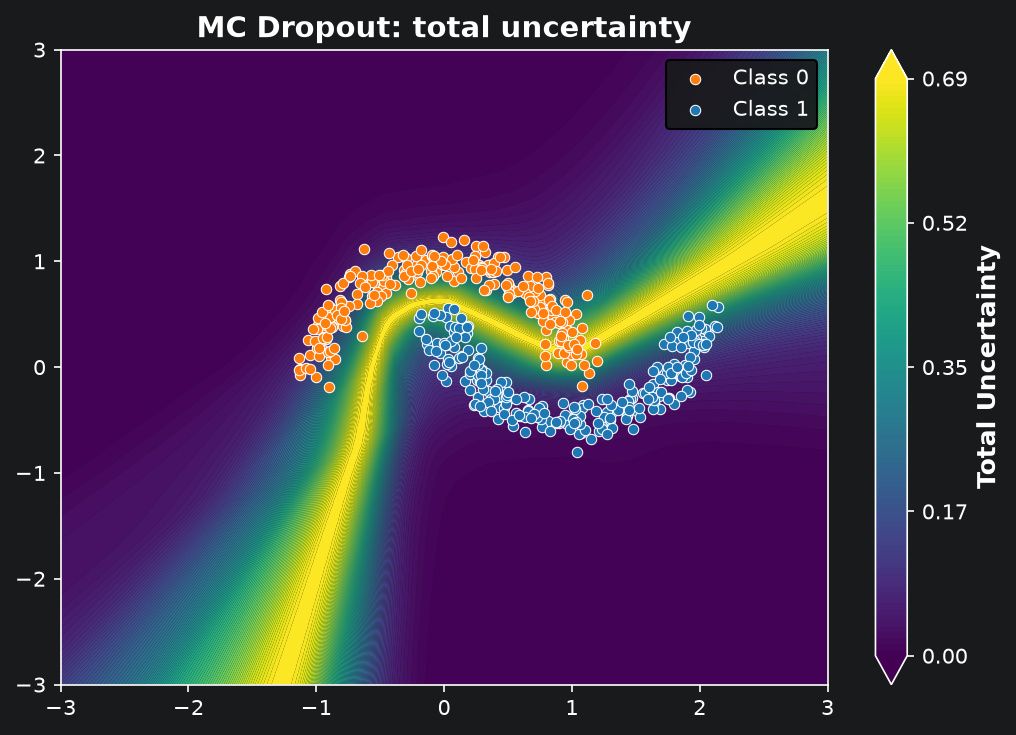

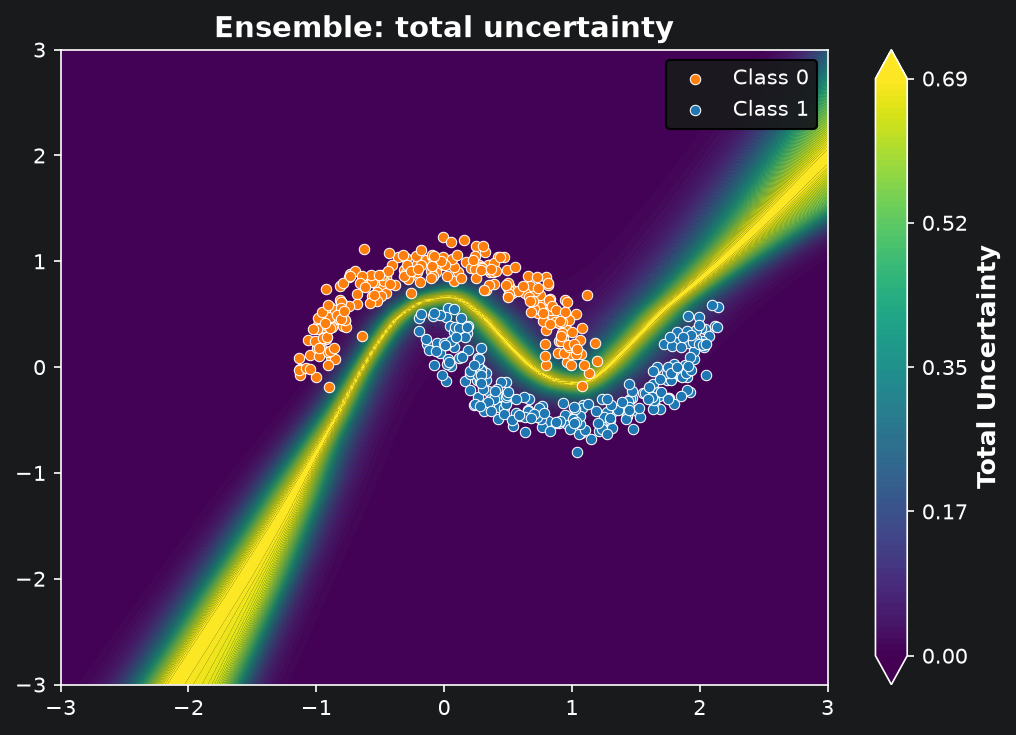

In [5]:
# 1. Dropout
for name, m in [("MC Dropout", dropout_model), ("Ensemble", ens_model)]:
    rep_dropout = representer(dropout_model, num_samples=200)
plot_example_uncertainty(X, y, rep_dropout, title="MC Dropout: total uncertainty", notion="total").show()

# 2. Ensemble
rep_ens = representer(ens_model)
plot_example_uncertainty(X, y, rep_ens, title="Ensemble: total uncertainty", notion="total").show()

## Attribution mit shapiq
Wichtig: Dropout ist stochastisch -> über T Pässe mitteln, sonst sind die
Shapley-Werte verrauscht und die Efficiency-Eigenschaft gilt nicht.
**Probly** (zur Messung der prädiktiven Entropie des Ensembles) und **shapiq** (zur Berechnung von Shapley-Werten) miteinander kombiniert:

* **Attribution auf Punktvorhersagen:** Erklärung der Vorhersagewahrscheinlichkeit $P(\text{Klasse 1})$ für einen maximal sicheren und einen maximal unsicheren Datenpunkt.
* **Attribution auf Unsicherheit:** Anwendung von Shapley-Werten auf die prädiktive Entropie, um zu klären, welche Merkmale ($x_1, x_2$) die Modellunsicherheit an einem konkreten Punkt antreiben.
* **Globale Entropie-Attribution:** Dekomposition der Entropie über ein 2D-Gitter zur räumlichen Analyse der Feature-Beiträge im gesamten Eingaberaum.

### (a) Lokale Sicht: Vorhersage vs. Prädiktive Entropie

* **Sicherer Punkt (tief im Cluster der Klasse 0):**
  * **Vorhersage $P(\text{Klasse 1})$:** Beide Merkmale ($x_1$ und $x_2$) weisen negative Shapley-Werte auf ($\phi_{x1} \approx -0.27$, $\phi_{x2} \approx -0.23$). Sie ziehen die Wahrscheinlichkeit gemeinsam stark nach unten ($f(x) - \mathbb{E}[f] = -0.50$), was eine eindeutige Zuordnung zu Klasse 0 bewirkt.
  * **Prädiktive Entropie:** Die SHAP-Beiträge zur Entropie liegen nahezu bei null ($\phi \approx 0$, $f(x) - \mathbb{E}[f] = -0.05$). Das Merkmalsprofil entspricht der bekannten Datenverteilung, weshalb keine Unsicherheit induziert wird.

* **Unsicherer Punkt (in der Überlappungszone):**
  * **Vorhersage $P(\text{Klasse 1})$:** Das Merkmal $x_2$ zieht die Zuordnung stark nach oben ($\phi_{x2} \approx +0.31$), während $x_1$ entgegenwirkt ($\phi_{x1} \approx -0.22$). Dies führt zu einer knappen Entscheidung nahe der Klassengrenze ($f(x) - \mathbb{E}[f] = +0.09$).
  * **Prädiktive Entropie:** Beide Merkmale leisten **positive Beiträge zur Modellunsicherheit** ($\phi_{x1} \approx +0.28$, $\phi_{x2} \approx +0.35$). Sie erhöhen die Entropie gemeinsam um $+0.63$ über den Basiswert bis nahe an das theoretische Maximum ($\approx 0.69$).


### (b) Globale Sicht: Attribuierung der Entropie im Eingaberaum

* **Entropie-Feld (Probly-Perspektive):**
  * Zeigt den charakteristischen S-förmigen Unsicherheitsgürtel entlang der Entscheidungsgrenze zwischen den beiden Mondsicheln.

* **Spatiale Feature-Aufteilung ($\phi_{x1}$ vs. $\phi_{x2}$):**
  * **$\phi_{x1}$ auf Entropie:** Erzeugt hohe positive SHAP-Werte (rot markiert) an den äußeren linken und rechten Flanken des Eingaberaums. Das Merkmal $x_1$ treibt die Unsicherheit vor allem an den Rändern der Verteilung.
  * **$\phi_{x2}$ auf Entropie:** Dominiert das Zentrum des Gürtels, an dem die beiden Mondsicheln vertikal ineinandergreifen.
  * **Fazit:** Während Probly aufdeckt, *wo* das Modell unsicher ist, visualisiert `shapiq`, *welche Koordinate* in welcher Region des Raumes für das Ansteigen der Unsicherheit verantwortlich ist.

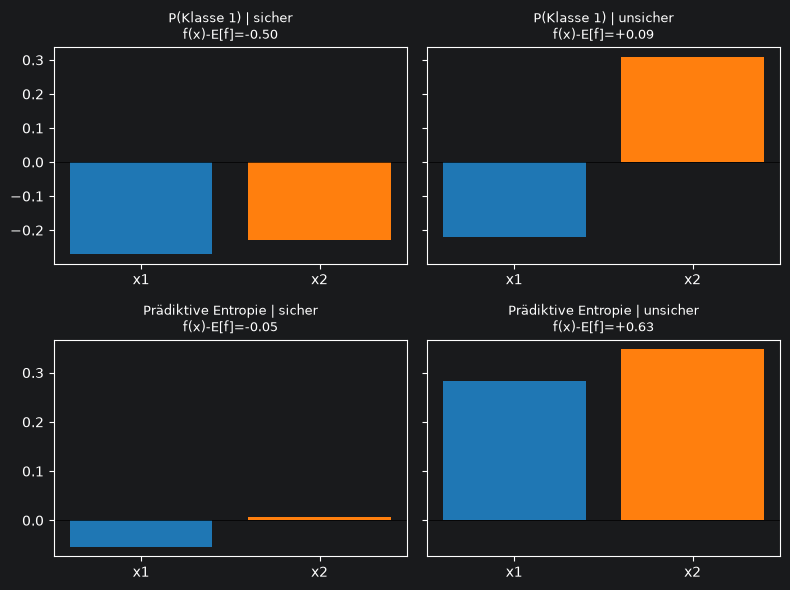

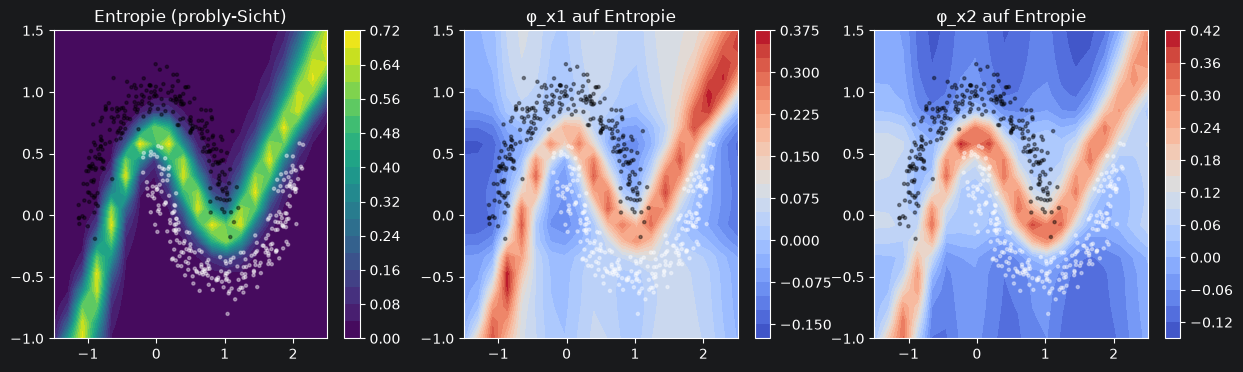

In [8]:
@torch.no_grad()
def proba_ens(a):
    x = torch.from_numpy(np.asarray(a)).float()
    return torch.stack([torch.softmax(mm(x), -1) for mm in ens_model]).mean(0).numpy()

def entropy(a):
    p = np.clip(proba_ens(a), 1e-12, 1)
    return -(p * np.log(p)).sum(1)

def shap_values(fn, x):
    # sample_size=None nutzt alle Hintergrunddaten und verhindert die UserWarning
    ex = shapiq.TabularExplainer(model=fn, data=X, index="SV", max_order=1, random_state=0, sample_size=None)
    iv = ex.explain(x, budget=4)
    return iv.baseline_value, iv.get_n_order_values(1)

# Punktauswahl über die tatsächliche Unsicherheit (nicht willkürlich)
H = entropy(X)
pts = {"sicher": X[np.argmin(H)], "unsicher": X[np.argmax(H)]}
targets = {"P(Klasse 1)": lambda a: proba_ens(a)[:, 1], "Prädiktive Entropie": entropy}

# (a) Lokale Erklärung: Vorhersage vs. Unsicherheit, sicherer vs. unsicherer Punkt
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharey="row")
for r, (tn, fn) in enumerate(targets.items()):
    for c, (pn, x) in enumerate(pts.items()):
        base, phi = shap_values(fn, x)
        axes[r, c].bar(["x1", "x2"], phi, color=["tab:blue", "tab:orange"])
        axes[r, c].axhline(0, color="k", lw=0.5)
        axes[r, c].set_title(f"{tn} | {pn}\nf(x)-E[f]={fn(x[None])[0]-base:+.2f}", fontsize=9)
plt.tight_layout(); plt.show()

# (b) Globale Sicht: SHAP auf der Entropie über ein grobes Gitter
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 20), np.linspace(-1, 1.5, 20))
grid = np.c_[xx.ravel(), yy.ravel()]
phi = np.array([shap_values(entropy, p)[1] for p in grid])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, Z, t, cm in zip(ax, [entropy(grid), phi[:, 0], phi[:, 1]],
                       ["Entropie (probly-Sicht)", "φ_x1 auf Entropie", "φ_x2 auf Entropie"],
                       ["viridis", "coolwarm", "coolwarm"]):
    im = a.contourf(xx, yy, Z.reshape(xx.shape), 20, cmap=cm)
    a.scatter(X[:, 0], X[:, 1], c=y, s=5, cmap="gray", alpha=.4)
    a.set_title(t); plt.colorbar(im, ax=a)
plt.show()